# 🎨 Notebook 3 — Copolymers & Chemical Composition
| | |
|---|---|
| ⏱ Time | ~25 min |
| 🧭 Type | **steady state Monte Carlo** (book Ch. 3) |
| 🎯 You will learn | track *what* is in each chain · CCD · Bernoulli vs terminal model · bivariate (length × composition) maps |
| 🧰 Uses | Notebook 2's `grow_chain`, now with a second `Rnd` to pick the monomer |
| 📖 Book algorithms | *Styrene–MMA Copolymerization (Bernoullian)* · *Styrene/MMA Free-Radical Copolymerization* · *CCD post-processing* · *Bivariate CLD × CCD* |

Two monomers: **M1 = styrene (S)** and **M2 = methyl methacrylate (MMA)**. Each chain now carries two numbers: its length `n` and its number of M1 units `n1`. See *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture* for how the probabilities link to reactivity ratios and rate constants.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm
random.seed(7)
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3})

## 1 · Bernoulli model: every unit is a coin flip
Same chain-growth loop as before, plus one extra question at each step: **is the new unit M1?** (`Rnd ≤ f1`)

In [2]:
def grow_bernoulli(Pp, f1):
    n  = 1
    n1 = 1 if random.random() <= f1 else 0
    while random.random() <= Pp:          # propagate?
        n += 1
        if random.random() <= f1:         # which monomer?
            n1 += 1
    return n, n1

def run_bernoulli(N, Pp, f1, P_comb=0.0):
    D, N1 = [], []
    for _ in range(N):
        n, n1 = grow_bernoulli(Pp, f1)
        if random.random() <= P_comb:     # combination with a second chain
            m, m1 = grow_bernoulli(Pp, f1)
            n, n1 = n + m, n1 + m1
        D.append(n); N1.append(n1)
    return np.array(D), np.array(N1)

D, N1 = run_bernoulli(5, 0.99, 0.5)
for d, k in zip(D, N1):
    print(f"length {d:4d}   styrene units {k:4d}   F1 = {k/d:.3f}")

length   37   styrene units   18   F1 = 0.486
length  242   styrene units  121   F1 = 0.500
length   24   styrene units   12   F1 = 0.500
length  121   styrene units   74   F1 = 0.612
length   27   styrene units   16   F1 = 0.593


## 2 · The Chemical Composition Distribution (CCD)
For each chain, `F1 = n1/n`. Put chains into composition bins, **weighted by chain length** (= mass), normalize. That's the book's CCD post-processing in three lines of NumPy.

👀 **Watch:** short chains have a *broad* CCD, long chains a *narrow* one — fewer coin flips means more scatter (Trick #2 again!).

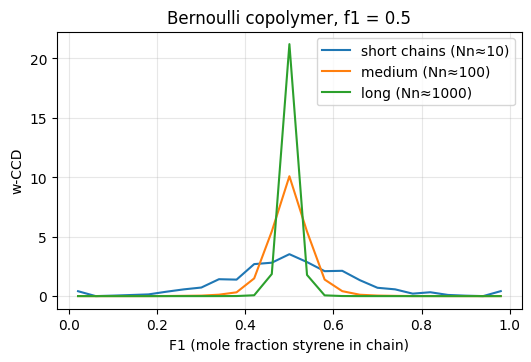

In [3]:
def ccd(D, N1, dF=0.04):
    F1 = N1 / D
    edges = np.arange(0, 1 + dF, dF)
    Y, _ = np.histogram(F1, bins=edges, weights=D)      # w-CCD: weight each chain by its length
    return 0.5*(edges[1:] + edges[:-1]), Y / Y.sum() / dF

for Pp, label in [(0.9, "short chains (Nn≈10)"), (0.99, "medium (Nn≈100)"), (0.999, "long (Nn≈1000)")]:
    D, N1 = run_bernoulli(20_000, Pp, 0.5)
    F, c = ccd(D, N1)
    plt.plot(F, c, label=label)
plt.xlabel("F1 (mole fraction styrene in chain)"); plt.ylabel("w-CCD")
plt.title("Bernoulli copolymer, f1 = 0.5"); plt.legend(); plt.show()

## 3 · Terminal model: the chain *remembers* its last unit
In real copolymerization the chance of adding M1 depends on the radical's **last unit**. With reactivity ratios `r1`, `r2` and feed fraction `f1`:

| last unit | P(add M1) |
|---|---|
| M1 | `r1·f1 / (r1·f1 + f2)` |
| M2 | `f1 / (f1 + r2·f2)` |

Each end group can also have its own propagation and termination probabilities (`P_p,1`, `P_p,2`, `P_tc,1`, `P_tc,2`).

In [4]:
def terminal_probs(f1, r1, r2):
    f2 = 1 - f1
    return {1: r1*f1/(r1*f1 + f2), 2: f1/(f1 + r2*f2)}

def grow_terminal(start, Pp, Padd1):
    last, n, n1 = start, 1, int(start == 1)
    while random.random() <= Pp[last]:
        n += 1
        if random.random() <= Padd1[last]:
            last = 1; n1 += 1
        else:
            last = 2
    return n, n1, last

def run_terminal(N, f1, r1=0.52, r2=0.46, Pp={1: 0.995, 2: 0.995}, Ptc={1: 0.9, 2: 0.3}):
    Padd1 = terminal_probs(f1, r1, r2)
    pick_start = lambda: 1 if random.random() <= f1 else 2
    D, N1, start = [], [], pick_start()
    while len(D) < N:
        n, n1, last = grow_terminal(start, Pp, Padd1)
        if random.random() <= Ptc[last]:                       # combination
            m, m1, _ = grow_terminal(pick_start(), Pp, Padd1)
            D.append(n + m); N1.append(n1 + m1)
        else:                                                  # transfer → seeds next chain
            D.append(n); N1.append(n1)
        start = pick_start()
    return np.array(D), np.array(N1)

### ✅ Validation: does the simulation obey the Mayo–Lewis equation?
Always check a new Monte Carlo code against a known answer. Here: the average copolymer composition vs feed composition.

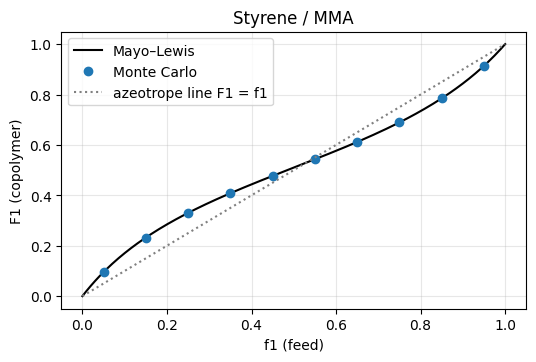

In [5]:
r1, r2 = 0.52, 0.46          # styrene / MMA, typical literature values
f_grid = np.linspace(0.05, 0.95, 10)
F_mc = []
for f1 in f_grid:
    D, N1 = run_terminal(3000, f1, r1, r2)
    F_mc.append(N1.sum() / D.sum())

f = np.linspace(0, 1, 200); f2 = 1 - f
F_ml = (r1*f**2 + f*f2) / (r1*f**2 + 2*f*f2 + r2*f2**2)
plt.plot(f, F_ml, "k-", label="Mayo–Lewis")
plt.plot(f_grid, F_mc, "o", label="Monte Carlo")
plt.plot([0, 1], [0, 1], ":", c="gray", label="azeotrope line F1 = f1")
plt.xlabel("f1 (feed)"); plt.ylabel("F1 (copolymer)"); plt.legend(); plt.title("Styrene / MMA"); plt.show()

## 4 · Seeing the sequences 👀
Same feed (`f1 = 0.5`), different chemistry. Each row is one chain, each square one unit (orange = M1, blue = M2).

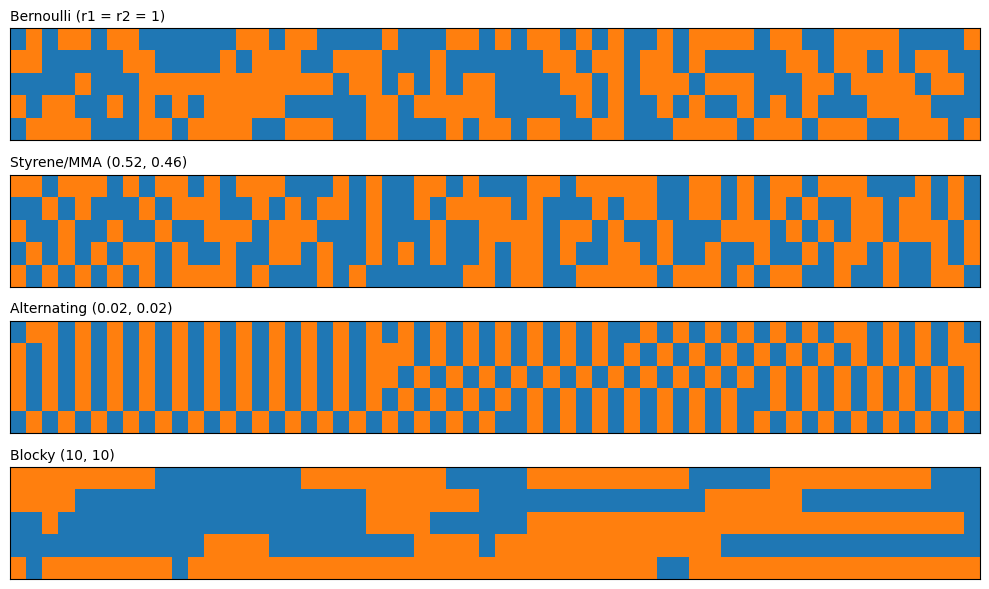

In [6]:
def sequence(L, f1, r1, r2):
    Padd1 = terminal_probs(f1, r1, r2)
    seq = [1 if random.random() <= f1 else 2]
    while len(seq) < L:
        seq.append(1 if random.random() <= Padd1[seq[-1]] else 2)
    return seq

cases = {"Bernoulli (r1 = r2 = 1)": (1, 1), "Styrene/MMA (0.52, 0.46)": (0.52, 0.46),
         "Alternating (0.02, 0.02)": (0.02, 0.02), "Blocky (10, 10)": (10, 10)}
fig, axes = plt.subplots(len(cases), 1, figsize=(10, 6))
for ax, (title, (a, b)) in zip(axes, cases.items()):
    ax.imshow([sequence(60, 0.5, a, b) for _ in range(5)], cmap=ListedColormap(["tab:orange", "tab:blue"]),
              aspect="auto", vmin=1, vmax=2)
    ax.set_title(title, fontsize=10, loc="left"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

## 5 · Bivariate map: chain length × composition
Instead of two separate distributions, look at both at once — a 2D histogram weighted by chain length (book: *Construction of Bivariate CLD × CCD*). Short chains are used here so the composition spread is visible, and the colors are on a log scale.

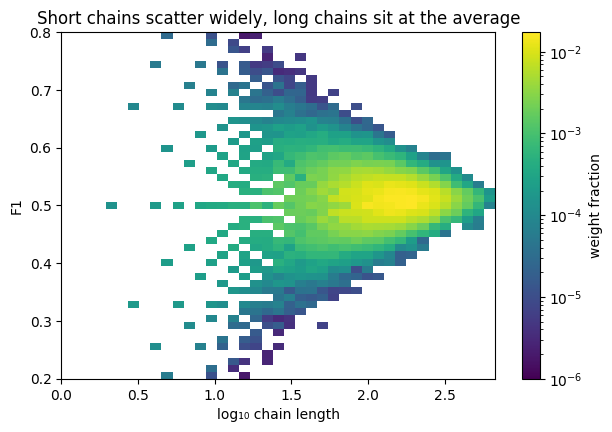

In [7]:
D, N1 = run_terminal(100_000, 0.5, Pp={1: 0.98, 2: 0.98})
F1 = N1 / D

n_edges = np.logspace(0, np.log10(D.max() + 1), 40)
F_edges = np.linspace(0.2, 0.8, 50)            # zoom on the interesting region
M, _, _ = np.histogram2d(D, F1, bins=[n_edges, F_edges], weights=D)
M = M / M.sum()                       # normalize

fig, ax = plt.subplots(figsize=(7, 4.5))
pc = ax.pcolormesh(np.log10(n_edges), F_edges, M.T, cmap="viridis", shading="flat",
                   norm=LogNorm(vmin=1e-6, vmax=M.max()))   # log colors show the faint short chains
fig.colorbar(pc, label="weight fraction")
ax.set_xlabel("log₁₀ chain length"); ax.set_ylabel("F1"); ax.grid(False)
ax.set_title("Short chains scatter widely, long chains sit at the average"); plt.show()

## ✅ Recap
- A second `Rnd` per step decides **which** monomer adds → composition tracking for free.
- **Bernoulli**: no memory. **Terminal model**: probabilities depend on the last unit.
- The CCD narrows with chain length; the bivariate map shows both effects together.
- Validate! (Mayo–Lewis.)

### 🧪 Try it yourself
1. Find the azeotrope of styrene/MMA (where F1 = f1). Hint: zoom into the validation plot.
2. Change `r1, r2` to `(10, 10)` in the bivariate map. What happens to the composition spread?
3. Add a third array that counts the longest M1 run in each chain.

➡️ **Next: Notebook 4 — Long-chain branching** (the full styrene/MMA case study with the book's parameters is Notebook 9)